# CSCI 645 HW2: Imitation learning for robot pick-and-place (Diffusion Policy)

The saved outputs in this notebook are from the run used in the report (Google Colab, one T4 GPU).

Run it **either** on Google Colab (T4) **or** on a CARC GPU node (OnDemand JupyterLab with the
`Python (hw2)` kernel from `slurm/setup_carc.sh`). Don't mix platforms inside one sweep, because
GPU simulation differs slightly across GPU types.

Every cell only calls the scripts in `code/`, so the notebook does exactly what the command-line /
SLURM workflow does. Steps are **resumable**: re-running a cell skips work that is already done.

| Section | What it does | Homework part |
|---|---|---|
| 0. Setup | settings, clone, Google Drive, install | – |
| 1. Checks | unit tests, smoke test, training-speed benchmark | – |
| 2. Demonstrations | collect 100 expert demos; statistics, figures, videos | Part 1 |
| 3. Teacher evaluation | expert on the 100 held-out test seeds | Parts 1, 4 |
| 4. Sanity check (optional) | overfit 5 demos | – |
| 5. Training sweep | 100 / 50 / 25 demos × 3 seeds: train + evaluate | Parts 2–3 |
| 6. Results | baseline vs. ablation table and comparison figures | Part 4 |
| 7. Failure analysis | layout coverage and rollout frames (CPU only) | Part 4 |
| 8. Save code edits | commit edits made on the runtime | – |

**Storage (Colab):** all outputs go to `My Drive/CSCI-645 Homework 2/pick-and-place-swing/`. That covers checkpoints and raw rollouts in `runs/`,
copies of `data/`, `results/` and `videos/`, and a log of every command in `logs/`. A disconnect therefore never
loses a trained model. Python packages and the git clone live on the VM and are reinstalled each session.

**Rules for edits:** change behaviour through `--set key=value` overrides where possible. If you
edit a `.py` file on the runtime, commit + push it (section 8) before the session ends.

## 0. Setup (run every session)
Settings, clone / pull the repo, mount Google Drive and install packages. The clone cell asks for an
optional GitHub token, only needed to push results back to the repo (press Enter to skip).

In [10]:
# ---- 0. Settings ----------------------------------------------------------------------------
REPO_URL = "https://github.com/kaustubhadhe1206/Panda-Pick-and-Place-Imitation.git"   # never put a token here
BRANCH = "main"
GIT_NAME, GIT_EMAIL = "kashinadhe", "kaustubhadhe@gmail.com"
DRIVE_FOLDER = "CSCI-645 Homework 2/pick-and-place-swing"   # Colab: all outputs are stored in My Drive/<this folder>
# (the older "pick-and-place" folder holds results from the earlier layout; it is not used anymore)

import os, sys, subprocess, pathlib, shlex
IN_COLAB = os.path.isdir("/content") and not os.environ.get("SLURM_JOB_ID")
cwd = pathlib.Path.cwd()
if (cwd / "code" / "hw2").is_dir():
    REPO = cwd
elif (cwd.parent / "code" / "hw2").is_dir():
    REPO = cwd.parent                                  # notebook opened from notebooks/ (CARC)
else:
    REPO = pathlib.Path("/content" if IN_COLAB else pathlib.Path.home()) / pathlib.Path(REPO_URL).stem
print("platform:", "Colab" if IN_COLAB else "CARC/other", "| repo:", REPO)

platform: Colab | repo: /content/Panda-Pick-and-Place-Imitation


In [11]:
# ---- 1. Clone / pull (public repo: no token needed) -----------------------------------------
# A token is OPTIONAL and only used to push results (CSVs, figures, videos) back to GitHub, so
# they show up in the repo without downloading them from Drive. Press Enter to skip it.
# If used: fine-grained token for this one repo, permission "Contents: Read and write".
from getpass import getpass
if "GH_TOKEN" not in os.environ:
    os.environ["GH_TOKEN"] = getpass("GitHub token for pushing results (Enter to skip): ").strip()
TOKEN = os.environ["GH_TOKEN"]
CAN_PUSH = bool(TOKEN)
if CAN_PUSH:
    os.environ["HW2_PUSH_URL"] = REPO_URL.replace("https://", f"https://x-access-token:{TOKEN}@")
else:
    os.environ.pop("HW2_PUSH_URL", None)               # run_sweep.py --push then skips pushing
print("GitHub push:", "enabled" if CAN_PUSH else "disabled (outputs are kept on Drive only)")

def run_git(*args, check=True):
    # Run a git command and print its output (with the token hidden).
    result = subprocess.run(["git", *args], cwd=REPO if REPO.exists() else None, capture_output=True, text=True)
    output = result.stdout + result.stderr
    if TOKEN: output = output.replace(TOKEN, "***")
    if output.strip(): print(output.strip())
    if check and result.returncode: raise RuntimeError(f"git {args[0]} failed")
    return result

if "<" in REPO_URL:
    raise ValueError("Set REPO_URL in cell 0 to your GitHub repo first.")
if not (REPO / ".git").exists():
    run_git("clone", "-q", "-b", BRANCH, REPO_URL, str(REPO))
else:
    run_git("pull", "--ff-only", REPO_URL, BRANCH)
if CAN_PUSH:
    run_git("config", "user.name", GIT_NAME); run_git("config", "user.email", GIT_EMAIL)
os.chdir(REPO)
run_git("log", "--oneline", "-3")

GitHub push: disabled (outputs are kept on Drive only)
Updating a5f5c08..f314625
Fast-forward
 code/hw2/envs.py | 5 +++++
 1 file changed, 5 insertions(+)
From https://github.com/kaustubhadhe1206/Panda-Pick-and-Place-Imitation
 * branch            main       -> FETCH_HEAD
f314625 Download MuJoCo Menagerie before creating the pick-and-place env
a5f5c08 Speed up training, add a speed benchmark, use a new Drive folder
0df7246 Make the arm swing 45-60 degrees between pick and place


CompletedProcess(args=['git', 'log', '--oneline', '-3'], returncode=0, stdout='f314625 Download MuJoCo Menagerie before creating the pick-and-place env\na5f5c08 Speed up training, add a speed benchmark, use a new Drive folder\n0df7246 Make the arm swing 45-60 degrees between pick and place\n', stderr='')

In [12]:
# ---- 1b. Google Drive storage (Colab only) --------------------------------------------------
# My Drive/CSCI-645 Homework 2/pick-and-place-swing/
#   runs/      checkpoints + raw rollouts (repo's runs/ is a symlink here, so they survive disconnects)
#   data/ results/ videos/   copies of everything the pipeline produces (refreshed after each step)
#   logs/      full console output of every pipeline command
# Packages and the git clone stay on the VM disk (Drive is too slow for imports / git).
import shutil, datetime
STORAGE = None
if IN_COLAB:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        STORAGE = pathlib.Path("/content/drive/MyDrive") / DRIVE_FOLDER
    except Exception as error:
        print("WARNING: Google Drive could not be mounted (" + repr(error)[:200] + ").\n"
              "Outputs stay on the VM" + ("; results are still pushed to GitHub after each step." if CAN_PUSH
              else " and are LOST on disconnect. Re-run cell 1 with a GitHub token to push them."))
if STORAGE is not None:
    for folder in ["runs", "logs", "data", "results", "videos"]:
        (STORAGE / folder).mkdir(parents=True, exist_ok=True)
    runs_dir = REPO / "runs"
    if runs_dir.exists() and not runs_dir.is_symlink():   # move anything made before Drive was mounted
        shutil.copytree(runs_dir, STORAGE / "runs", dirs_exist_ok=True)
        shutil.rmtree(runs_dir)
    if not runs_dir.is_symlink():
        runs_dir.symlink_to(STORAGE / "runs", target_is_directory=True)
    os.environ["HW2_MIRROR_DIR"] = str(STORAGE)            # run_sweep.py copies each finished run here
    print("Drive storage:", STORAGE)
    saved_checkpoints = sorted(path.parent.name for path in (STORAGE / "runs").glob("*/checkpoint.pt"))
    print("existing checkpoints:", saved_checkpoints)

def copy_outputs_to_drive():
    # Copy data/, results/, videos/ from the repo into the Drive folder (does nothing without Drive).
    if STORAGE is None: return
    for folder in ["data", "results", "videos"]:
        if (REPO / folder).exists():
            shutil.copytree(REPO / folder, STORAGE / folder, dirs_exist_ok=True)
    print("saved to Drive:", STORAGE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive storage: /content/drive/MyDrive/CSCI-645 Homework 2/pick-and-place-swing
existing checkpoints: []


In [13]:
# ---- 2. Install (Colab only; CARC uses the venv built by slurm/setup_carc.sh) ----------------
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
    # Note: later, JAX may print "PJRT_Api already exists for device type cuda". That is harmless:
    # Colab already ships a JAX CUDA plugin and pip adds a second copy; JAX just uses the first one.
    # EGL vendor file for headless MuJoCo rendering on Colab GPUs (as in the Playground notebooks).
    egl_vendor_file = "/usr/share/glvnd/egl_vendor.d/10_nvidia.json"
    if not os.path.exists(egl_vendor_file):
        os.makedirs(os.path.dirname(egl_vendor_file), exist_ok=True)
        with open(egl_vendor_file, "w") as f:
            f.write('{"file_format_version" : "1.0.0", "ICD" : {"library_path" : "libEGL_nvidia.so.0"}}')
os.environ["MUJOCO_GL"] = "egl"
subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,driver_version", "--format=csv"])

def run_command(command):
    # Run a pipeline command from the repo root, show its output live (and save it to a log on Drive).
    print("$", command, flush=True)
    log_file = None
    if STORAGE is not None:
        script_name = "-".join(pathlib.Path(arg).stem for arg in shlex.split(command)[1:3])
        log_file = open(STORAGE / "logs" / f"{datetime.datetime.now():%Y%m%d-%H%M%S}_{script_name}.log", "w")
        log_file.write(f"$ {command}\n")
    process = subprocess.Popen(shlex.split(command), cwd=REPO, stdout=subprocess.PIPE,
                               stderr=subprocess.STDOUT, text=True)
    for line in process.stdout:
        print(line, end="")
        if log_file: log_file.write(line); log_file.flush()
    exit_code = process.wait()
    if log_file: log_file.close()
    if exit_code: raise RuntimeError(f"command failed ({exit_code}): {command}")

def save_and_push(paths, message):
    # Copy outputs to Drive, then (if a token was given) commit the given paths and push to GitHub.
    copy_outputs_to_drive()
    if not CAN_PUSH: return print("GitHub push skipped (no token)")
    paths = [path for path in paths if (REPO / path).exists()]
    if not paths: return print("nothing to push")
    run_git("add", "-f", *paths)
    if run_git("diff", "--cached", "--quiet", check=False).returncode:
        run_git("commit", "-q", "-m", message)
        run_git("push", "-q", os.environ["HW2_PUSH_URL"], f"HEAD:{BRANCH}")
        print("pushed:", message)
    else:
        print("nothing to commit")

from IPython.display import Image, Video, display, Markdown

## 1. Checks
### Unit tests and smoke test
CPU unit tests, then versions, GPU, environment sizes, expert success on 50 seeds, a rendered video
and a speed estimate (summarized in the final `SMOKE TEST REPORT` block). To tune the expert, re-run
with overrides, e.g.
`run_command("python code/smoke_test.py --checks env expert render --set expert.approach_speed=0.025")`.

In [14]:
run_command("python tests/test_cpu.py")
run_command("python code/smoke_test.py")

$ python tests/test_cpu.py
ok test_pick_and_place_layout (0.0s)
ok test_window_time_indices (0.0s)
ok test_normalizer (0.0s)
ok test_unet_output_shape (0.0s)
ok test_sampler_recovers_point_with_perfect_noise_prediction (0.0s)
ok test_policy_learns_and_checkpoint_roundtrip (5.8s)
ok test_episodes_success_and_replay (0.0s)
ok test_failure_labels (0.0s)
ok test_policy_controller_replans_every_action_horizon (1.1s)
ok test_config_overrides (0.0s)
4 demos -> 92 windows | obs (2, 66) actions (16, 8) | device cpu
policy parameters: 0.13 M
step     30 loss 1.20794 lr 0.00e+00 27.1 it/s eta 0.0 min
{
  "num_demos": 4,
  "num_windows": 92,
  "num_params": 125120,
  "train_time_s": 1.1062119007110596,
  "final_loss": 1.2079429626464844
}
4 demos -> 92 windows | obs (2, 66) actions (16, 8) | device cpu
policy parameters: 0.13 M
stopped after 15 steps at step 15; state saved to /tmp/tmp5siwykc9/resumed/train_state.pt
4 demos -> 92 windows | obs (2, 66) actions (16, 8) | device cpu
policy parameters

### Training speed benchmark (~2 min)
Compares speed settings on this GPU (random data, no simulator), summarized in the `TRAINING SPEED`
block. All runs in the report use the default fp32. A different setting must be used for the *whole*
sweep (`EXTRA_SETTINGS` in section 5), never for only some runs.

In [15]:
run_command("python code/benchmark_training.py")

$ python code/benchmark_training.py
plain                  7.04 steps/s ->   47.3 min for 20000 steps
+ cudnn benchmark      6.85 steps/s ->   48.7 min for 20000 steps
+ fused + foreach      6.80 steps/s ->   49.0 min for 20000 steps
+ fp16 (use_amp)      28.91 steps/s ->   11.5 min for 20000 steps

==== TRAINING SPEED (paste this back) ====
{
 "gpu": "Tesla T4",
 "torch": "2.11.0+cu130",
 "batch_size": 256,
 "num_steps": 20000,
 "results": [
  {
   "setting": "plain",
   "steps_per_second": 7.04,
   "minutes_per_run": 47.3
  },
  {
   "setting": "+ cudnn benchmark",
   "steps_per_second": 6.85,
   "minutes_per_run": 48.7
  },
  {
   "setting": "+ fused + foreach",
   "steps_per_second": 6.8,
   "minutes_per_run": 49.0
  },
  {
   "setting": "+ fp16 (use_amp)",
   "steps_per_second": 28.91,
   "minutes_per_run": 11.5
  }
 ]
}


### Smoke-test videos
Expert videos rendered by the smoke test above.

In [16]:
for video_path in ["videos/smoke/expert_smoke.mp4", "videos/smoke/expert_smoke_failure.mp4"]:
    if (REPO / video_path).exists():
        display(Markdown(f"`{video_path}`"), Video(str(REPO / video_path), embed=True, width=480))

`videos/smoke/expert_smoke.mp4`

## 2. Demonstrations (Part 1)
Collects 100 successful expert demos (env seeds 0–99), then makes the statistics, figures and videos
used in report Q1–Q2. Collection is skipped if `data/demos_baseline.npz` already exists (set
`FORCE = True` to collect again).

$ python code/collect_demos.py
Jax plugin configuration error: Exception when calling jax_plugins.xla_cuda13.initialize()
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/jax/_src/xla_bridge.py", line 495, in discover_pjrt_plugins
    plugin_module.initialize()
    ~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/jax_plugins/xla_cuda13/__init__.py", line 373, in initialize
    c_api = xb.register_plugin(
        'cuda', priority=500, library_path=str(path), options=options
    )
  File "/usr/local/lib/python3.13/dist-packages/jax/_src/xla_bridge.py", line 637, in register_plugin
    c_api = xla_client.load_pjrt_plugin_dynamically(plugin_name, library_path)
  File "/usr/local/lib/python3.13/dist-packages/jaxlib/xla_client.py", line 115, in load_pjrt_plugin_dynamically
    return _xla.load_pjrt_plugin(plugin_name, library_path, c_api=None)
           ~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
jax.errors.JaxRunt

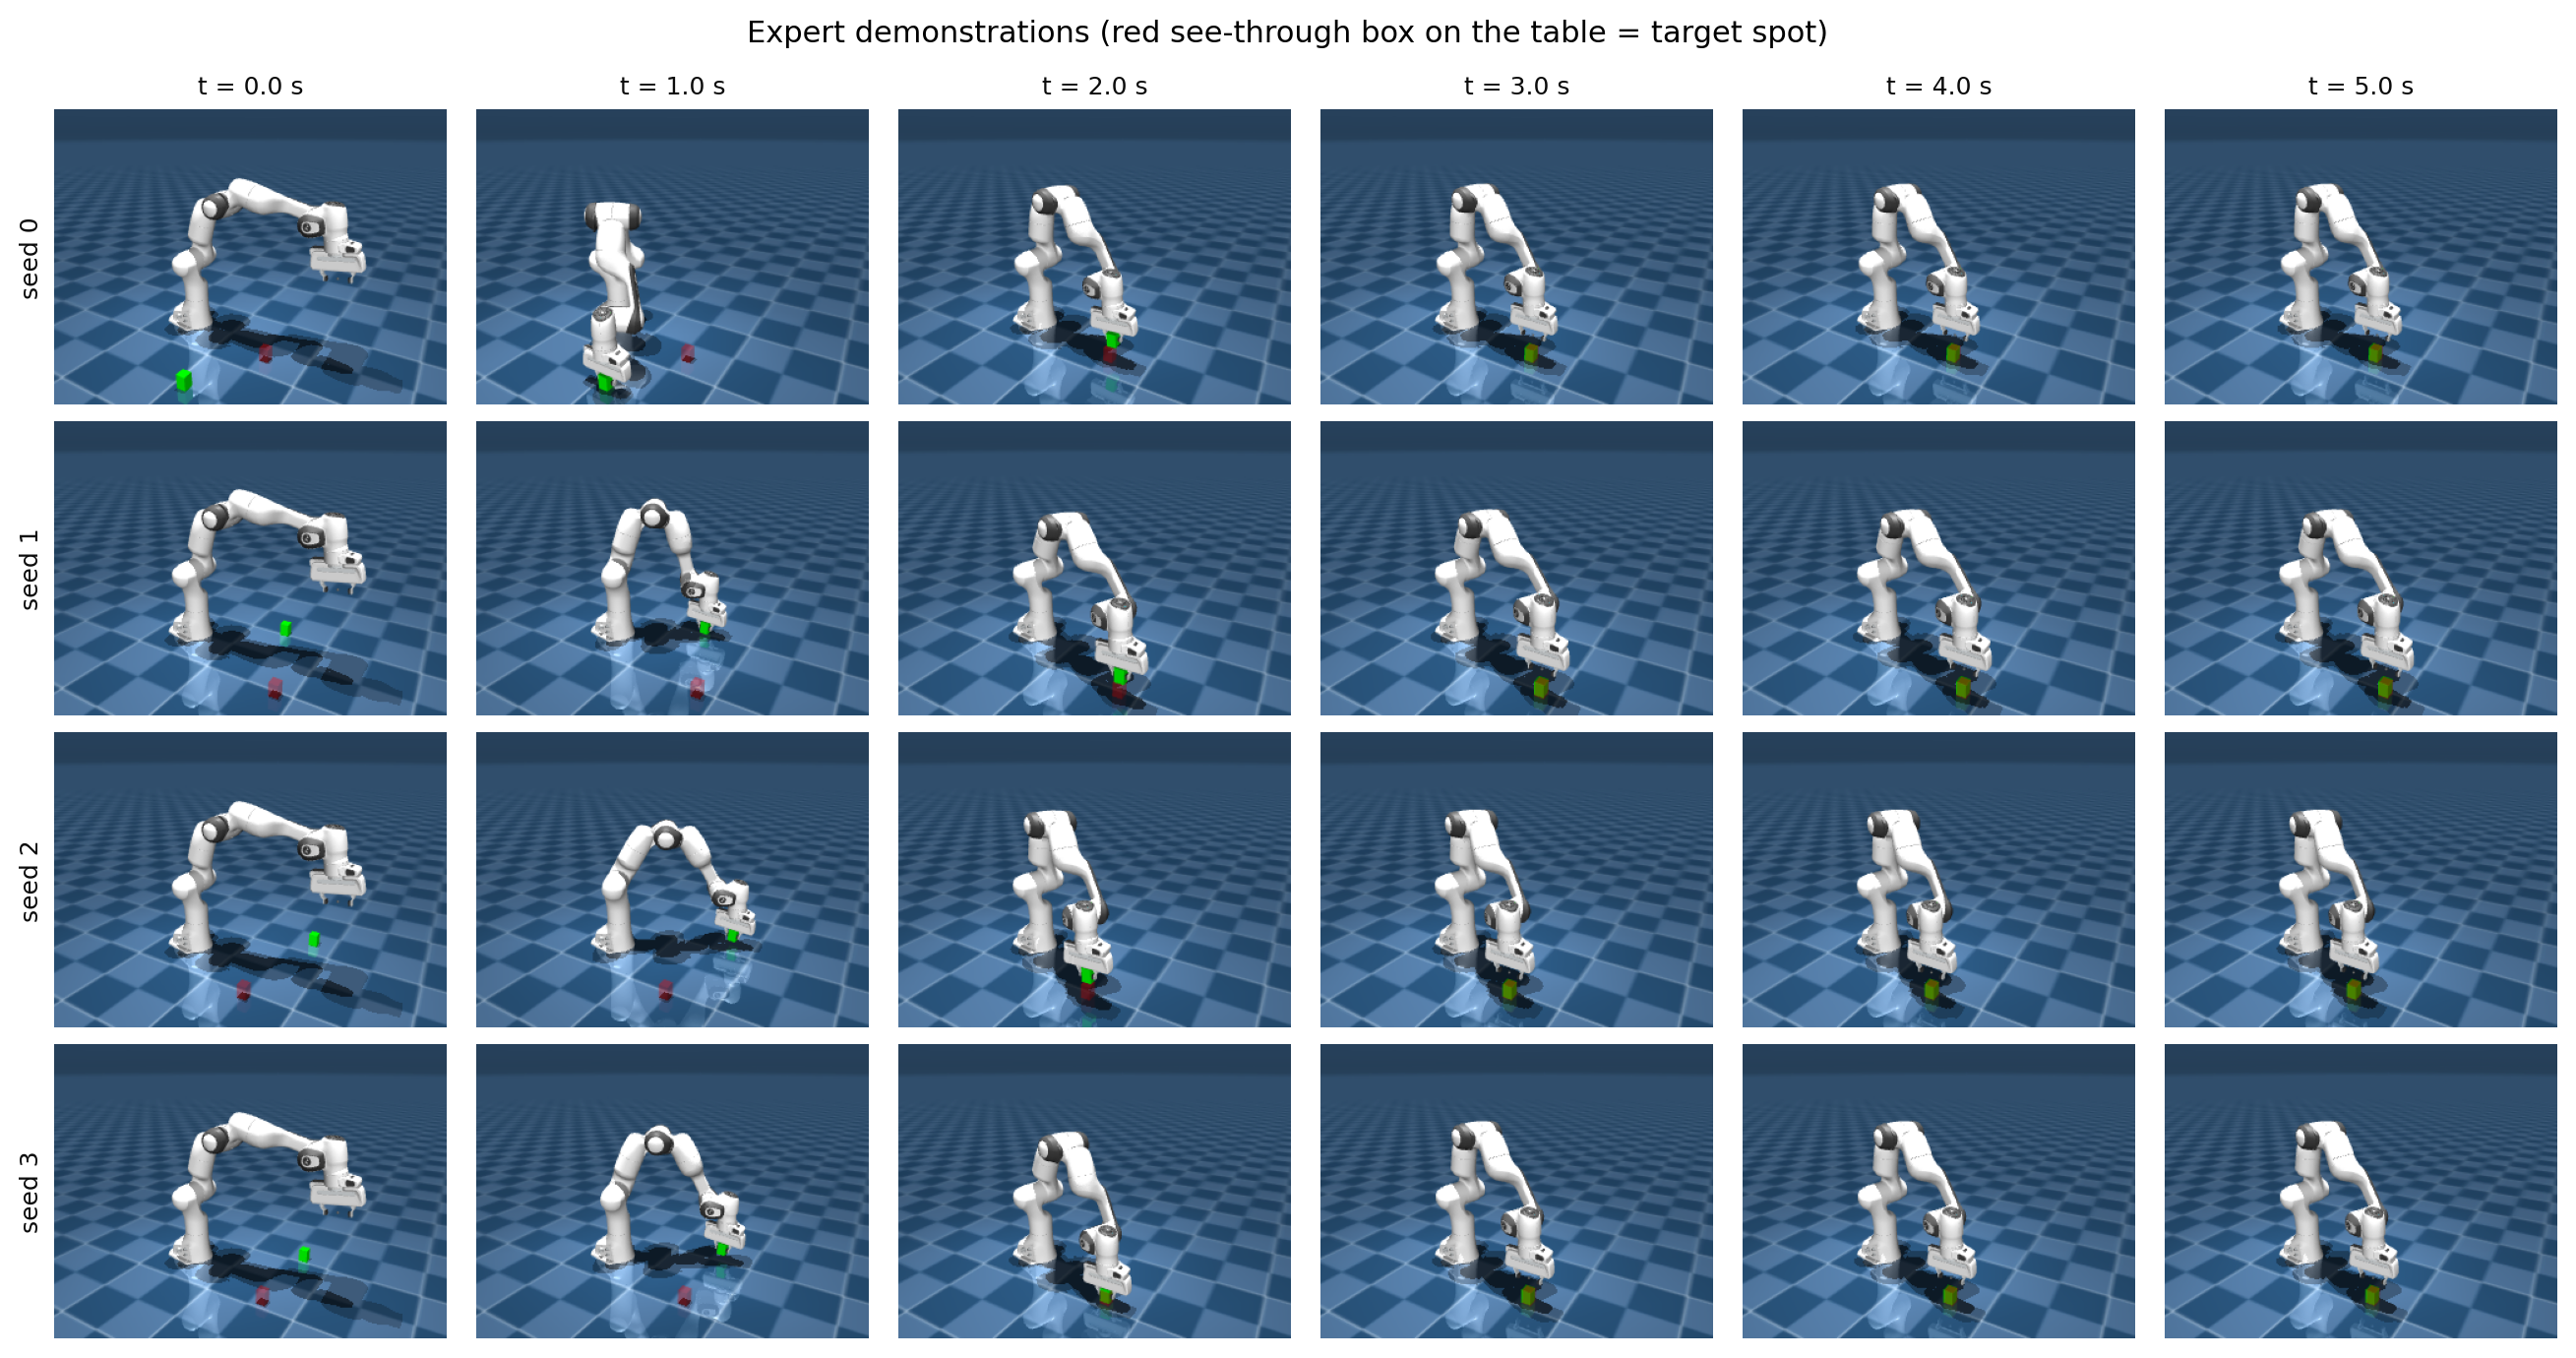

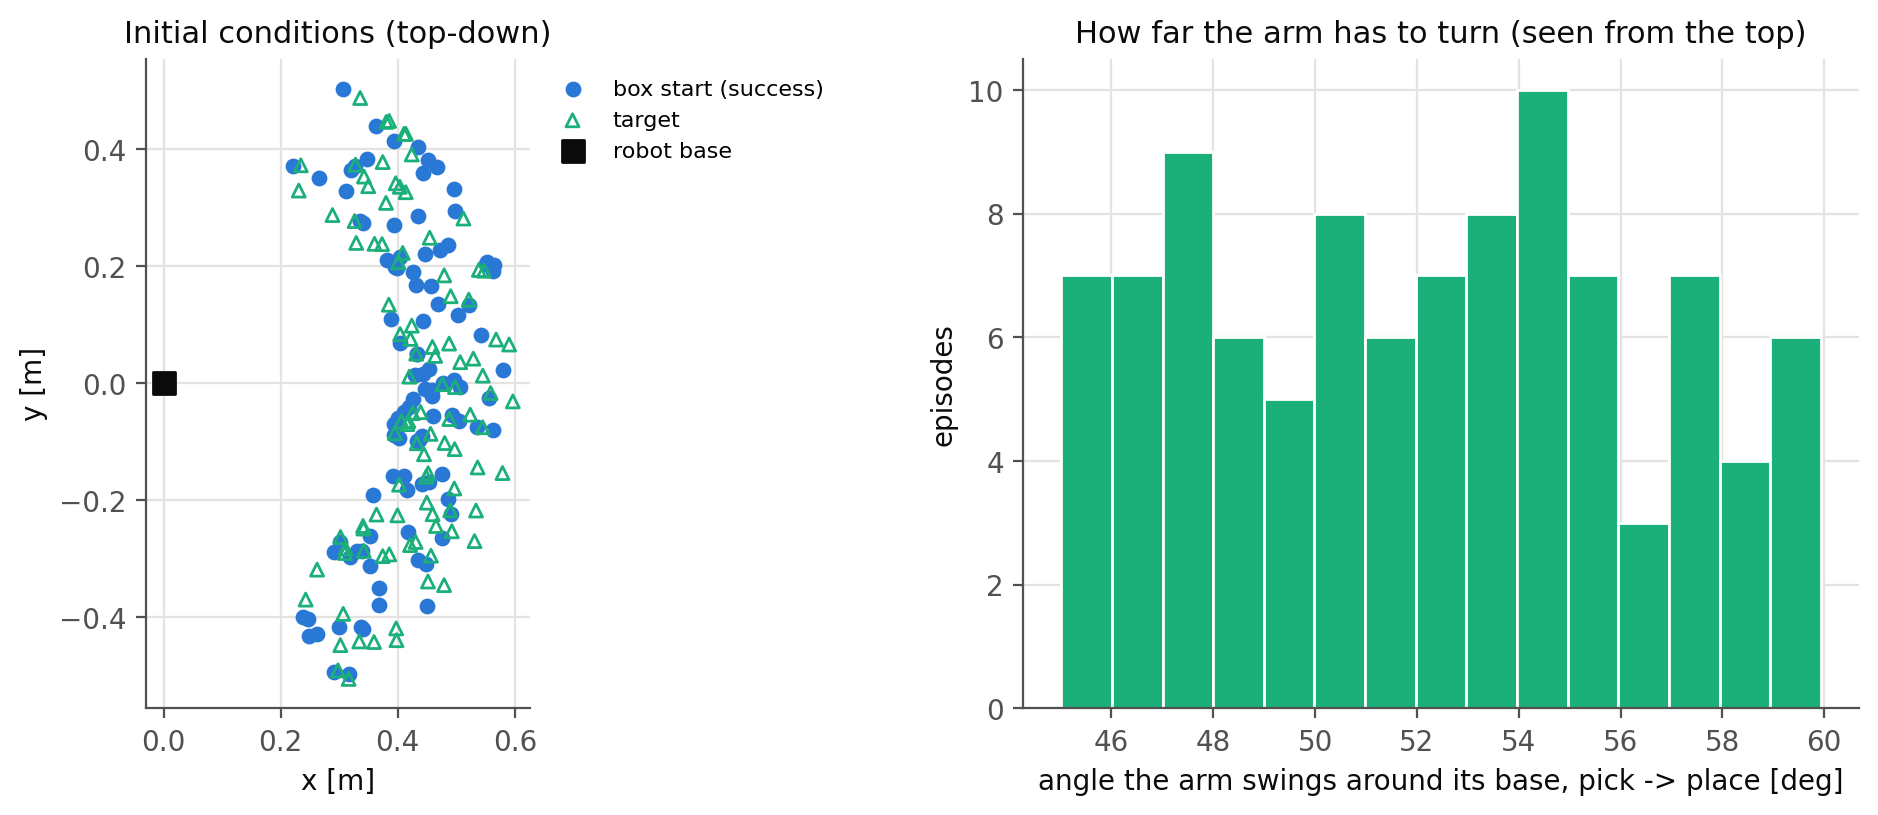

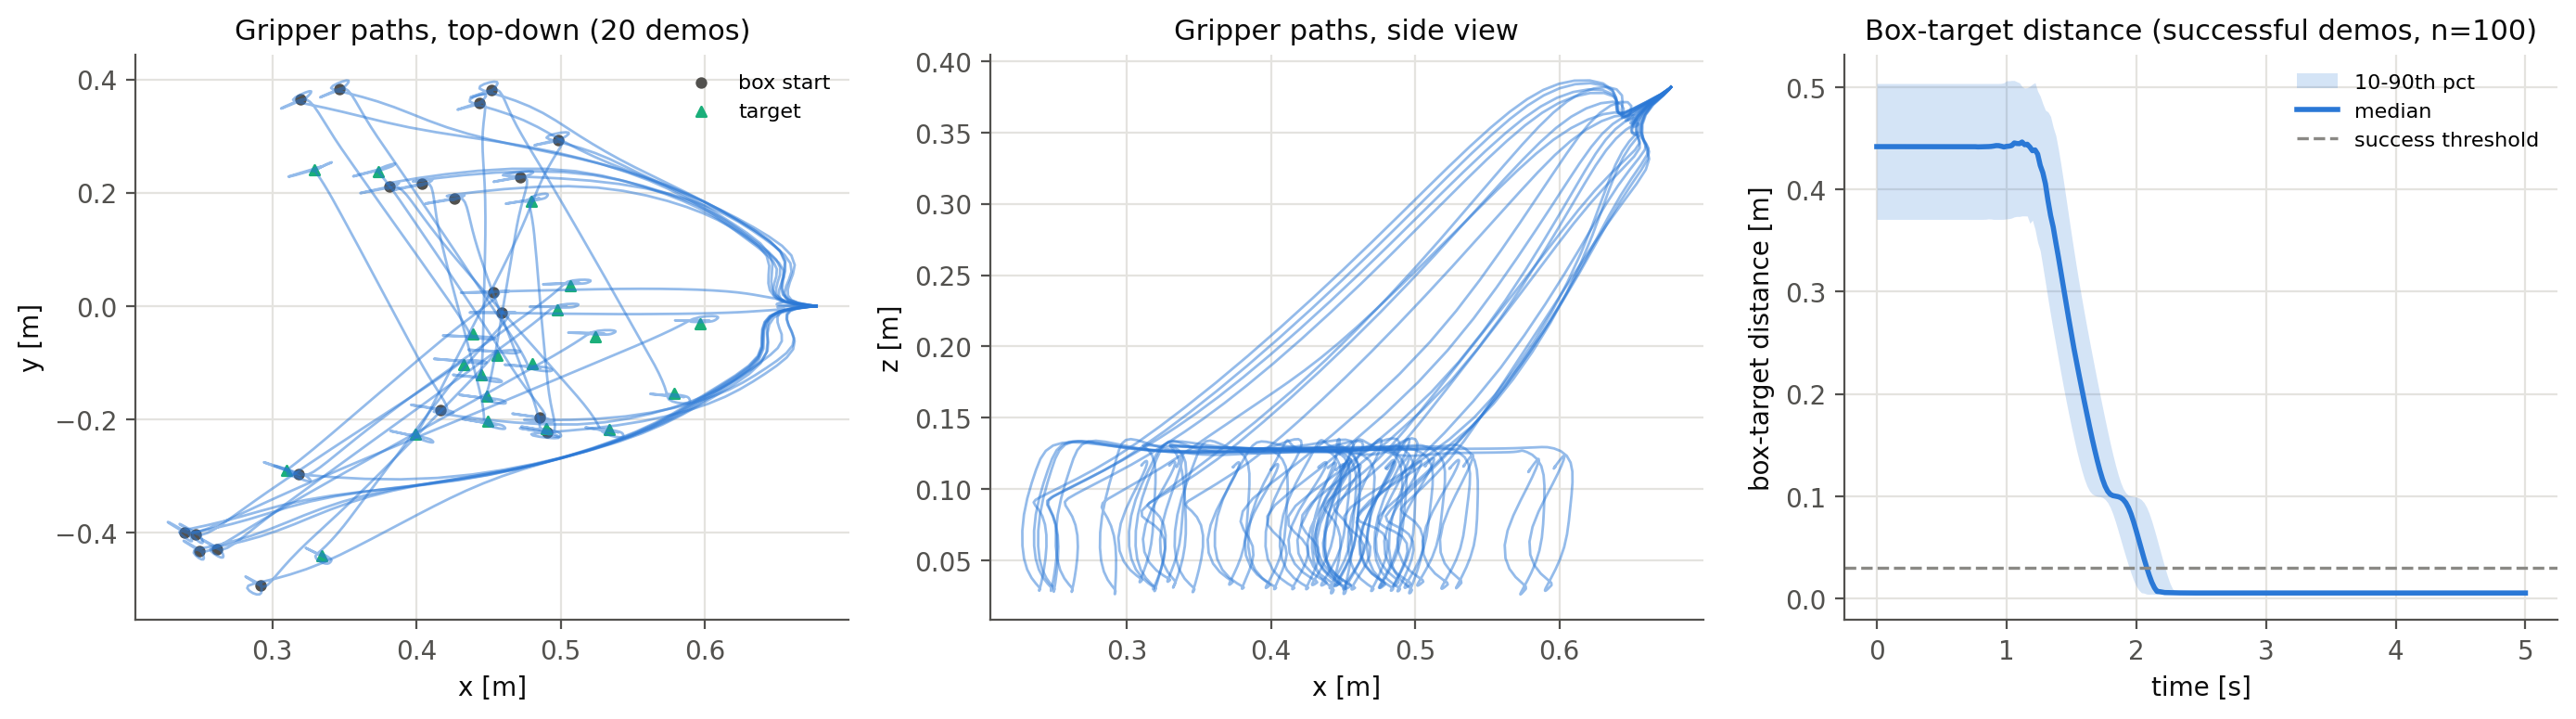

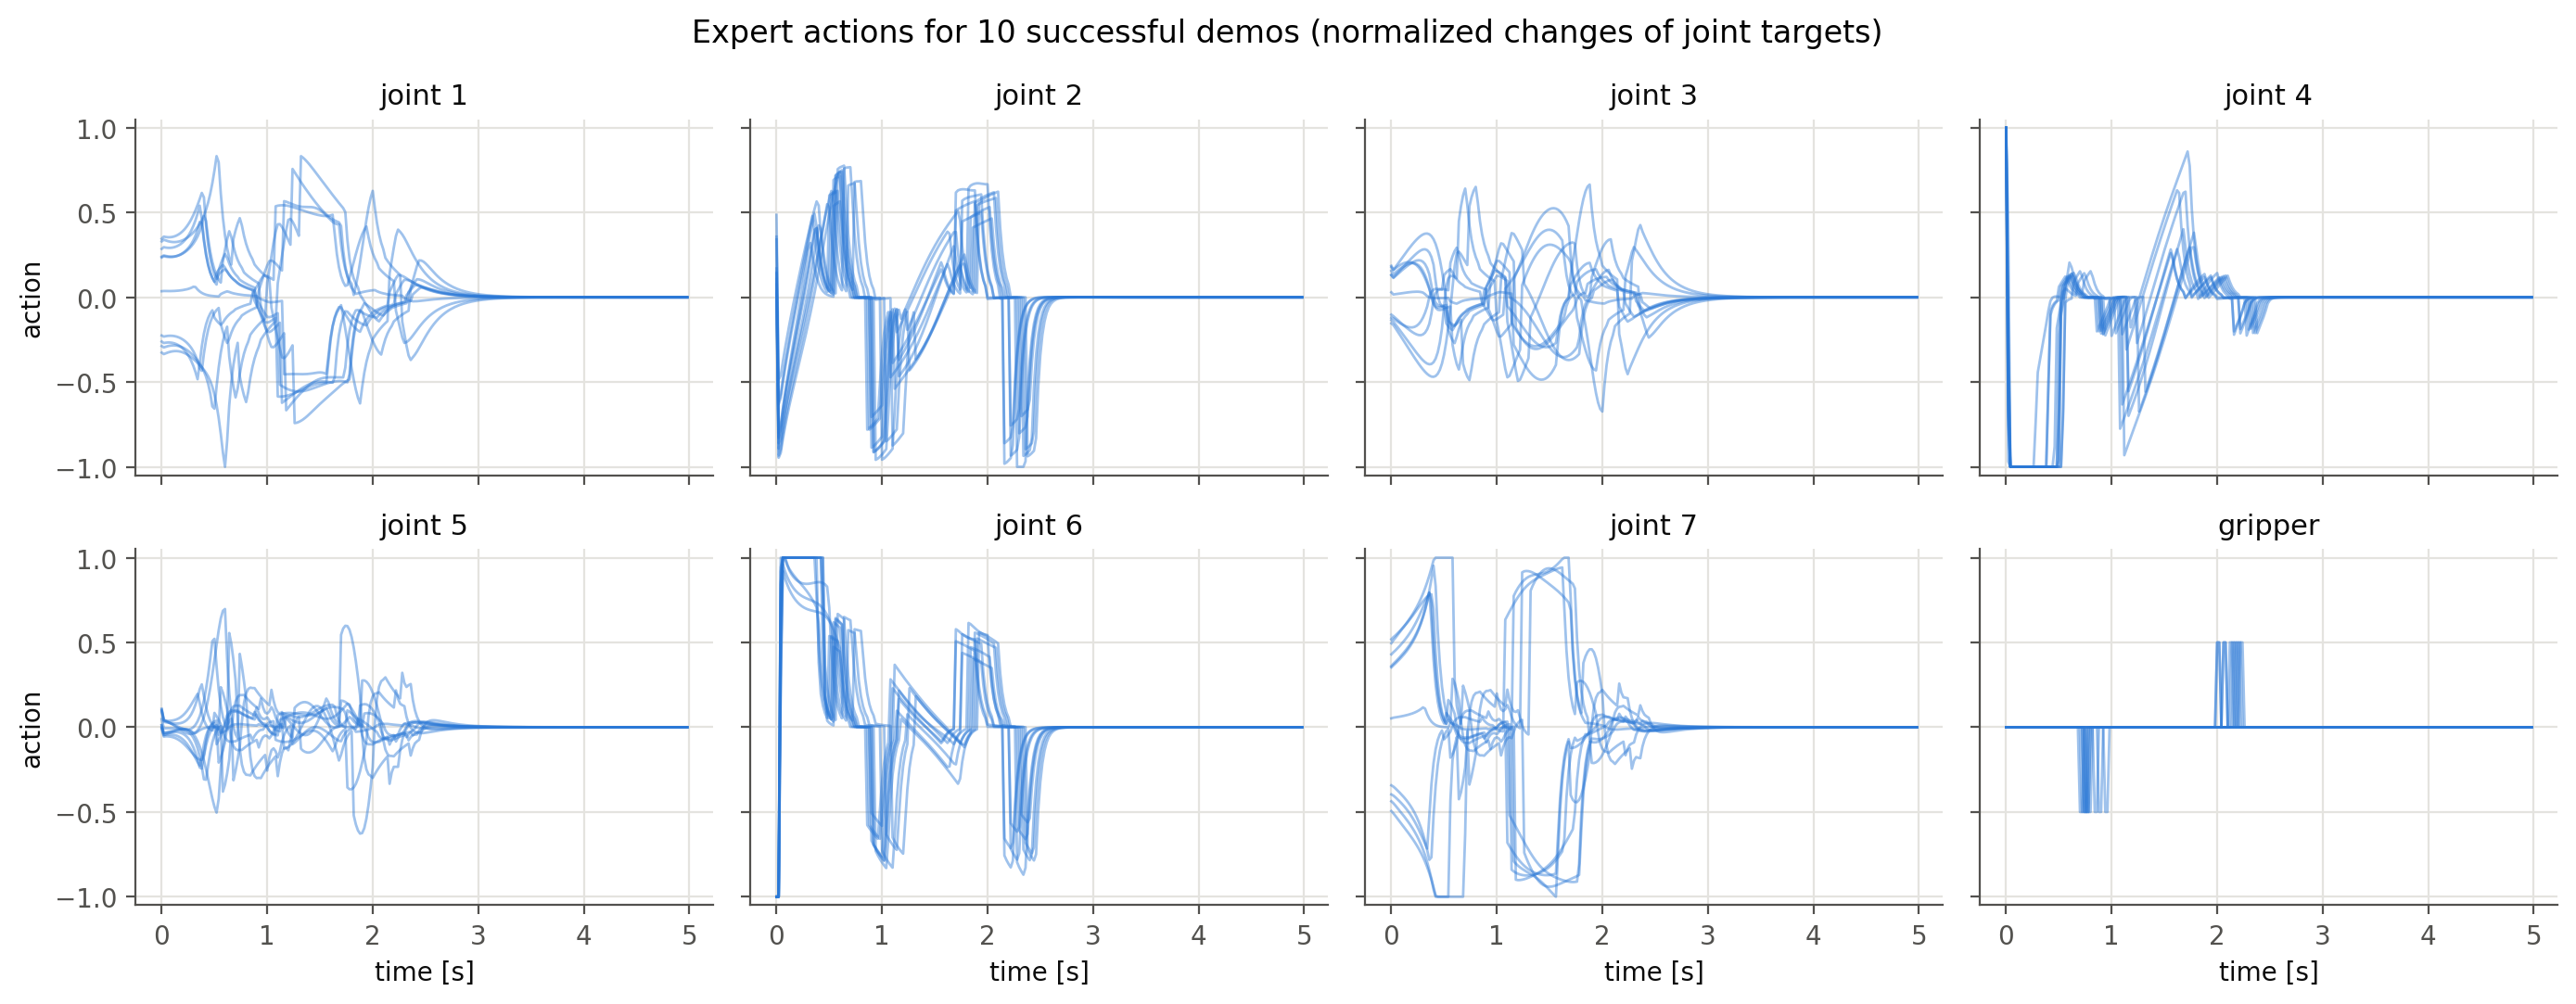

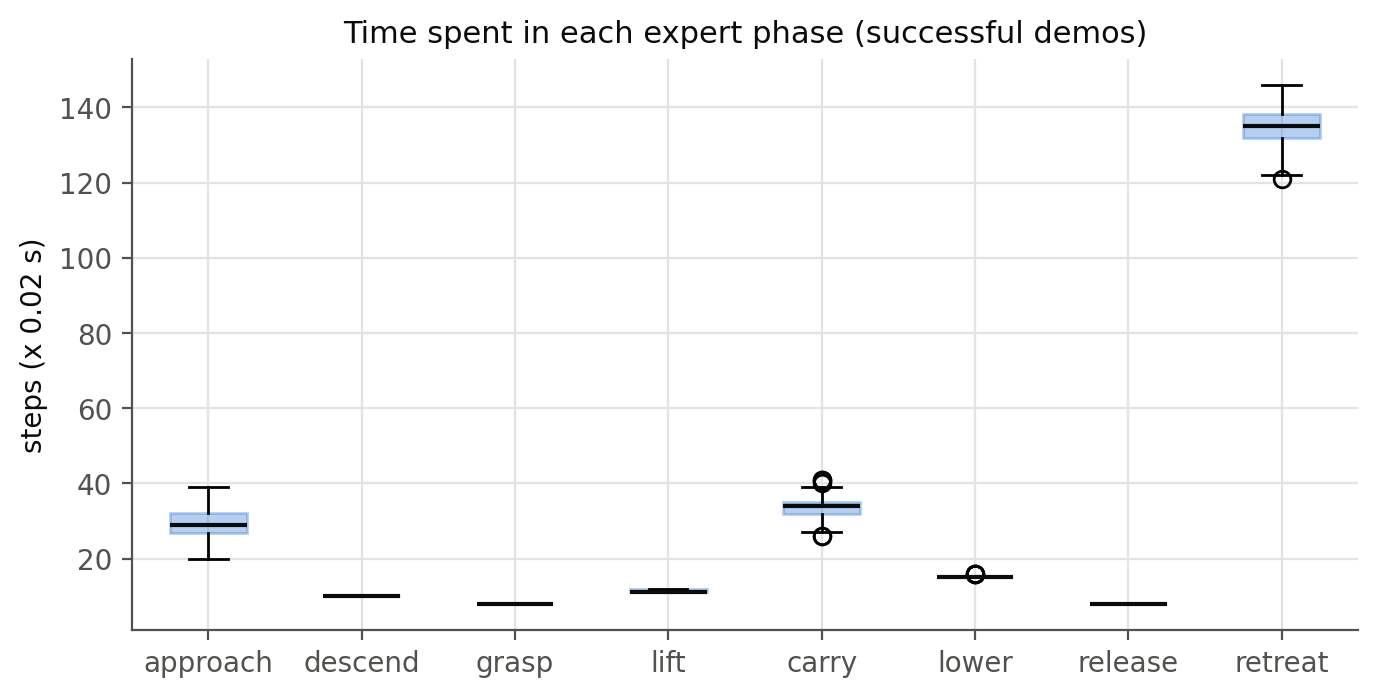

saved to Drive: /content/drive/MyDrive/CSCI-645 Homework 2/pick-and-place-swing
GitHub push skipped (no token)


In [17]:
FORCE = False
if FORCE or not (REPO / "data/demos_baseline.npz").exists():
    run_command("python code/collect_demos.py")
run_command("python code/inspect_demos.py")
for figure_name in ["fig_frames", "fig_coverage", "fig_trajectories", "fig_actions", "fig_phases"]:
    figure_path = REPO / f"results/demos/{figure_name}.png"
    if figure_path.exists(): display(Image(str(figure_path)))
grid_video = REPO / "videos/expert/expert_demos_grid.mp4"
if grid_video.exists(): display(Video(str(grid_video), embed=True, width=640))
save_and_push(["data/demos_baseline.npz", "results/demos", "videos/expert"], "demos: baseline dataset + inspection")

## 3. Teacher evaluation
Runs the expert on the 100 held-out test seeds (100000–100099), the same seeds every student is
tested on.

In [18]:
if not (REPO / "results/teacher_eval/eval_summary.json").exists():
    run_command("python code/evaluate.py --teacher --out-dir results/teacher_eval --video-dir videos/teacher_eval")
save_and_push(["results/teacher_eval", "videos/teacher_eval"], "results: teacher evaluation")

$ python code/evaluate.py --teacher --out-dir results/teacher_eval --video-dir videos/teacher_eval
Jax plugin configuration error: Exception when calling jax_plugins.xla_cuda13.initialize()
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/jax/_src/xla_bridge.py", line 495, in discover_pjrt_plugins
    plugin_module.initialize()
    ~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/jax_plugins/xla_cuda13/__init__.py", line 373, in initialize
    c_api = xb.register_plugin(
        'cuda', priority=500, library_path=str(path), options=options
    )
  File "/usr/local/lib/python3.13/dist-packages/jax/_src/xla_bridge.py", line 637, in register_plugin
    c_api = xla_client.load_pjrt_plugin_dynamically(plugin_name, library_path)
  File "/usr/local/lib/python3.13/dist-packages/jaxlib/xla_client.py", line 115, in load_pjrt_plugin_dynamically
    return _xla.load_pjrt_plugin(plugin_name, library_path, c_api=None)
           ~~~~~~~~~~~

## 4. Sanity check (optional)
Train on 5 demos and evaluate **on those same 5 seeds**. Near-perfect success here means the
data -> training -> execution path is wired correctly. Not part of the reported results.

In [19]:
RUN_SANITY = True
if RUN_SANITY:
    run_command("python code/train.py --run-dir runs/sanity_n5 --set data.num_demos=5 train.num_steps=3000 eval.batch_size=5")
    run_command("python code/evaluate.py --run-dir runs/sanity_n5 --on-train-seeds --out-dir results/sanity_n5 --num-videos 1")

$ python code/train.py --run-dir runs/sanity_n5 --set data.num_demos=5 train.num_steps=3000 eval.batch_size=5
5 demos -> 1215 windows | obs (2, 66) actions (16, 8) | device cuda
policy parameters: 17.27 M
step   1000 loss 0.03085 lr 9.05e-05 17.7 it/s eta 1.9 min
step   2000 loss 0.01432 lr 3.45e-05 17.3 it/s eta 1.0 min
step   3000 loss 0.01010 lr 0.00e+00 17.2 it/s eta 0.0 min
{
  "num_demos": 5,
  "num_windows": 1215,
  "num_params": 17270792,
  "train_time_s": 173.9144835472107,
  "final_loss": 0.010099838487803936
}
$ python code/evaluate.py --run-dir runs/sanity_n5 --on-train-seeds --out-dir results/sanity_n5 --num-videos 1
Jax plugin configuration error: Exception when calling jax_plugins.xla_cuda13.initialize()
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/jax/_src/xla_bridge.py", line 495, in discover_pjrt_plugins
    plugin_module.initialize()
    ~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/jax_plugins/xla_cu

## 5. Training sweep (Parts 2–3, resumable)
Runs `configs/sweep.yaml` (100 / 50 / 25 demos x seeds 0, 1, 2): train, then evaluate on the 100
test seeds. Each finished run is copied to Drive (and pushed to GitHub if a token was given).
Training saves a resumable state to Drive every 2000 steps (`runs/<run>/train_state.pt`), and a
finished run is never retrained. If the session dies, reconnect, run section 0, then this cell
again: finished runs are skipped and the interrupted run continues from its last saved step.

In [20]:
# Settings applied to EVERY run of the sweep, e.g. "--set train.use_amp=true" or "--set train.num_steps=10000".
# Decide before the first run and do not change them halfway, so all runs stay comparable.
EXTRA_SETTINGS = ""
run_command(f"python code/run_sweep.py --dry-run {EXTRA_SETTINGS}")
run_command(f"python code/run_sweep.py --push {EXTRA_SETTINGS}")

$ python code/run_sweep.py --dry-run 
[run] n100_s0: ['data.num_demos=100', 'seed=0']
[run] n50_s0: ['data.num_demos=50', 'seed=0']
[run] n25_s0: ['data.num_demos=25', 'seed=0']
[run] n100_s1: ['data.num_demos=100', 'seed=1']
[run] n50_s1: ['data.num_demos=50', 'seed=1']
[run] n25_s1: ['data.num_demos=25', 'seed=1']
[run] n100_s2: ['data.num_demos=100', 'seed=2']
[run] n50_s2: ['data.num_demos=50', 'seed=2']
[run] n25_s2: ['data.num_demos=25', 'seed=2']
$ python code/run_sweep.py --push 
[run] n100_s0: ['data.num_demos=100', 'seed=0']
  $ code/train.py --config configs/dp_base.yaml --run-dir /content/Panda-Pick-and-Place-Imitation/runs/n100_s0 --set data.num_demos=100 seed=0
100 demos -> 24300 windows | obs (2, 66) actions (16, 8) | device cuda
policy parameters: 17.27 M
step   1000 loss 0.03352 lr 9.98e-05 16.6 it/s eta 19.1 min
step   2000 loss 0.01912 lr 9.85e-05 16.9 it/s eta 17.8 min
step   3000 loss 0.01468 lr 9.60e-05 16.9 it/s eta 16.8 min
step   4000 loss 0.01176 lr 9.23e-05 1

## 6. Results (Part 4)
The baseline vs. ablation table, then success vs. number of demos, success vs. distance threshold,
failure modes, training loss and action smoothness.

$ python code/analyze.py
| Condition | Number of demonstrations | Teacher success rate (collection / eval seeds) | Student success rate (mean ± std over seeds) | Pooled [95% CI] | Evaluation episodes |
|---|---:|---:|---:|---:|---:|
| n100 | 100 | 100% / 100% | 70.7% ± 0.6% (3 seeds) | 212/300 [65-76%] | 100 per seed |
| n50 | 50 | 100% / 100% | 50.3% ± 2.1% (3 seeds) | 151/300 [45-56%] | 100 per seed |
| n25 | 25 | 100% / 100% | 8.7% ± 2.5% (3 seeds) | 26/300 [6-12%] | 100 per seed |

{
  "n100": [
    0.7,
    0.71,
    0.71
  ],
  "n50": [
    0.52,
    0.48,
    0.51
  ],
  "n25": [
    0.09,
    0.11,
    0.06
  ]
}


| Condition | Number of demonstrations | Teacher success rate (collection / eval seeds) | Student success rate (mean ± std over seeds) | Pooled [95% CI] | Evaluation episodes |
|---|---:|---:|---:|---:|---:|
| n100 | 100 | 100% / 100% | 70.7% ± 0.6% (3 seeds) | 212/300 [65-76%] | 100 per seed |
| n50 | 50 | 100% / 100% | 50.3% ± 2.1% (3 seeds) | 151/300 [45-56%] | 100 per seed |
| n25 | 25 | 100% / 100% | 8.7% ± 2.5% (3 seeds) | 26/300 [6-12%] | 100 per seed |


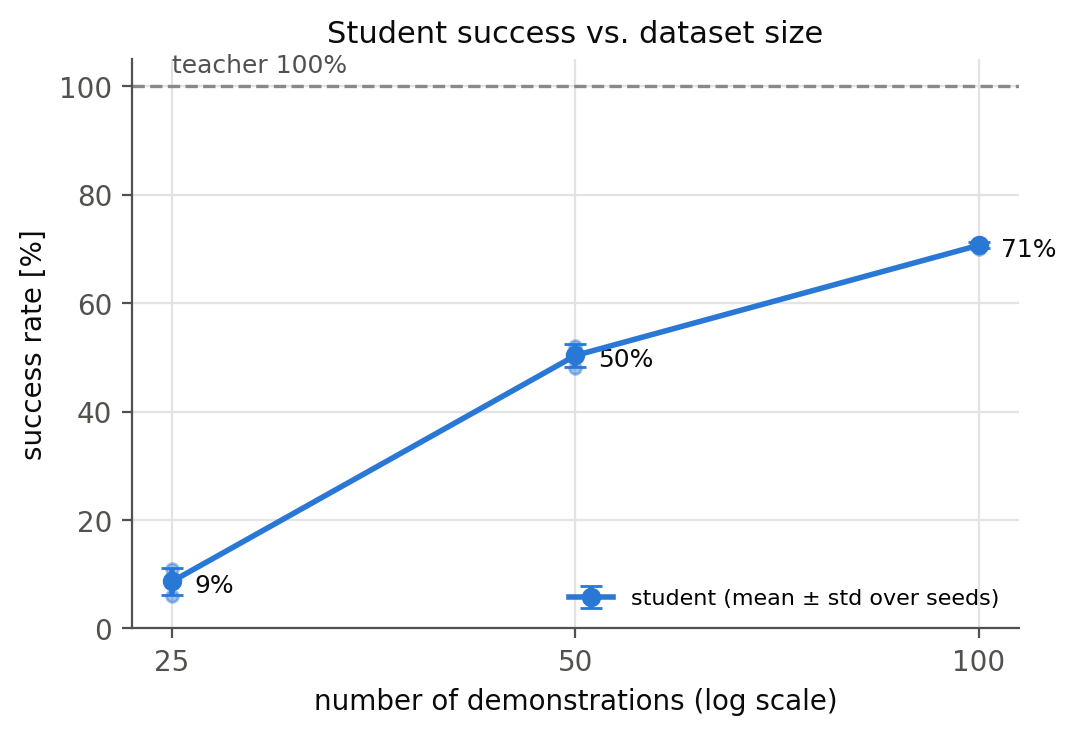

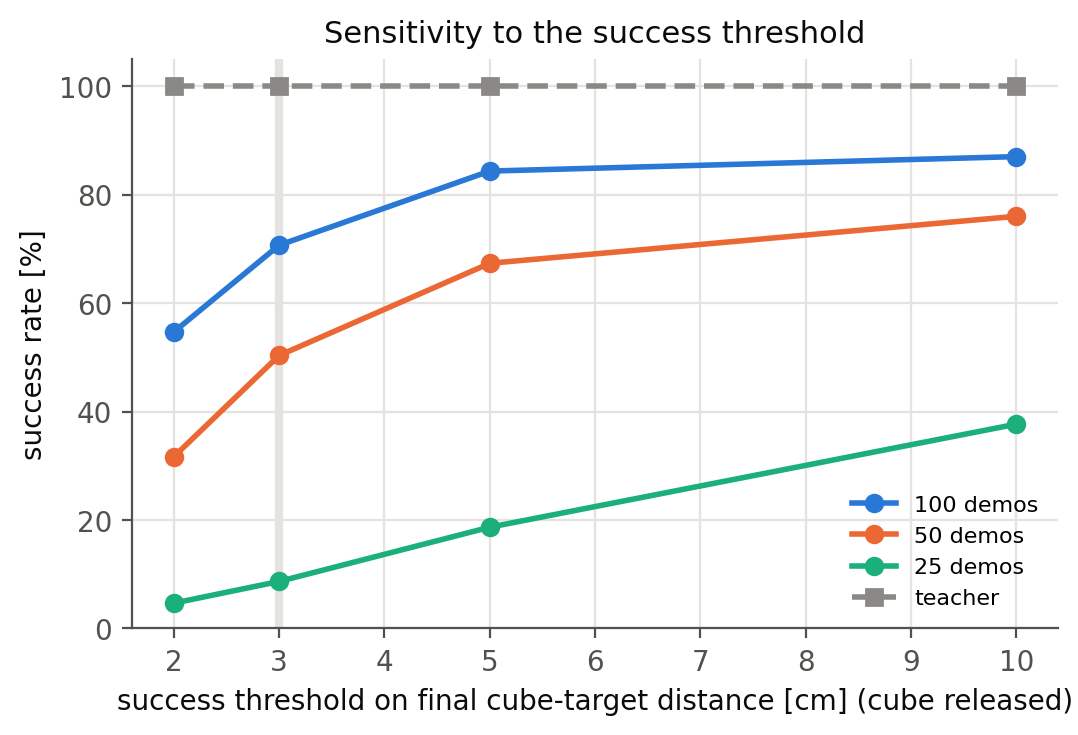

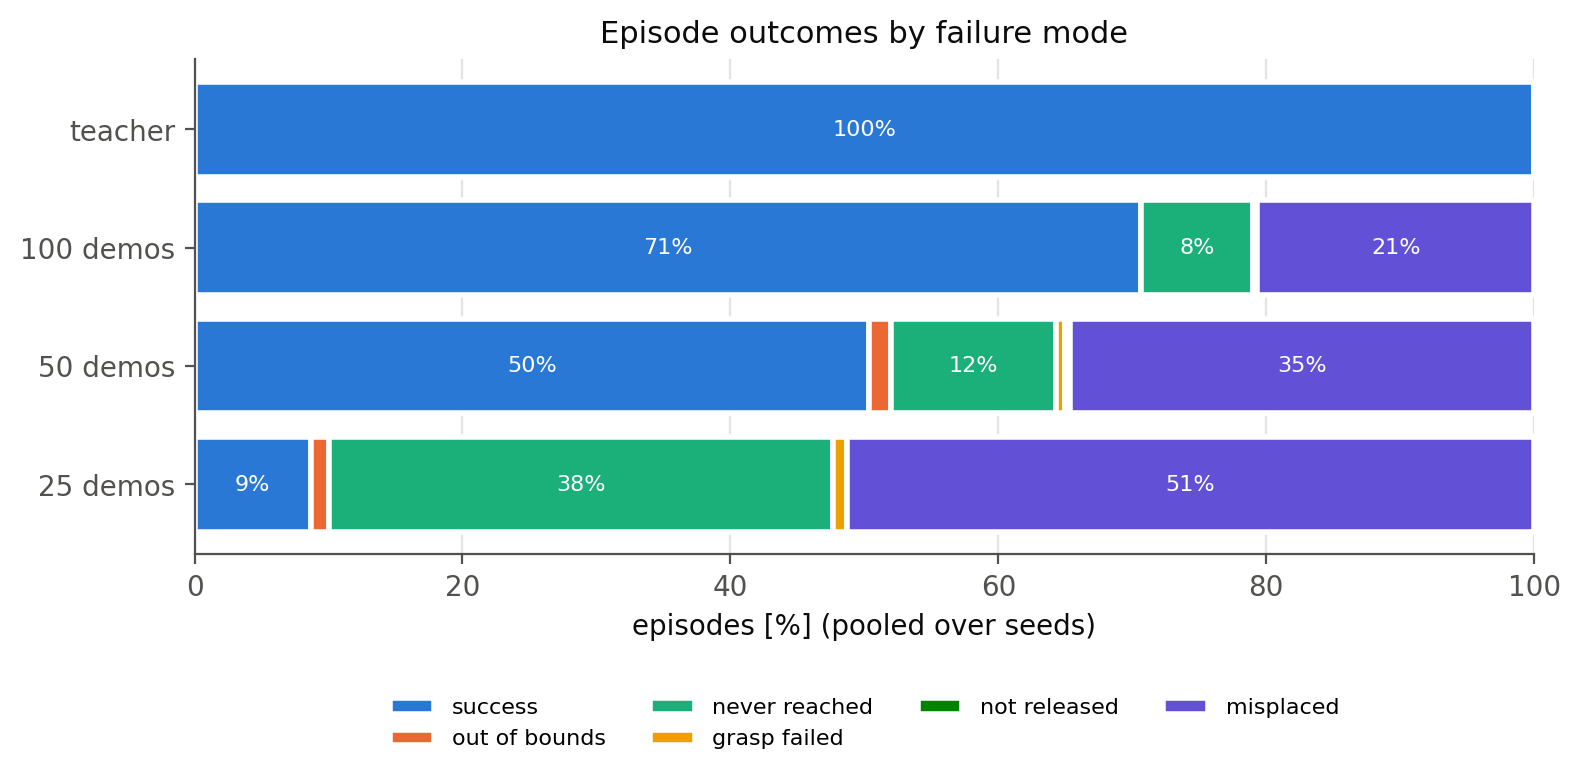

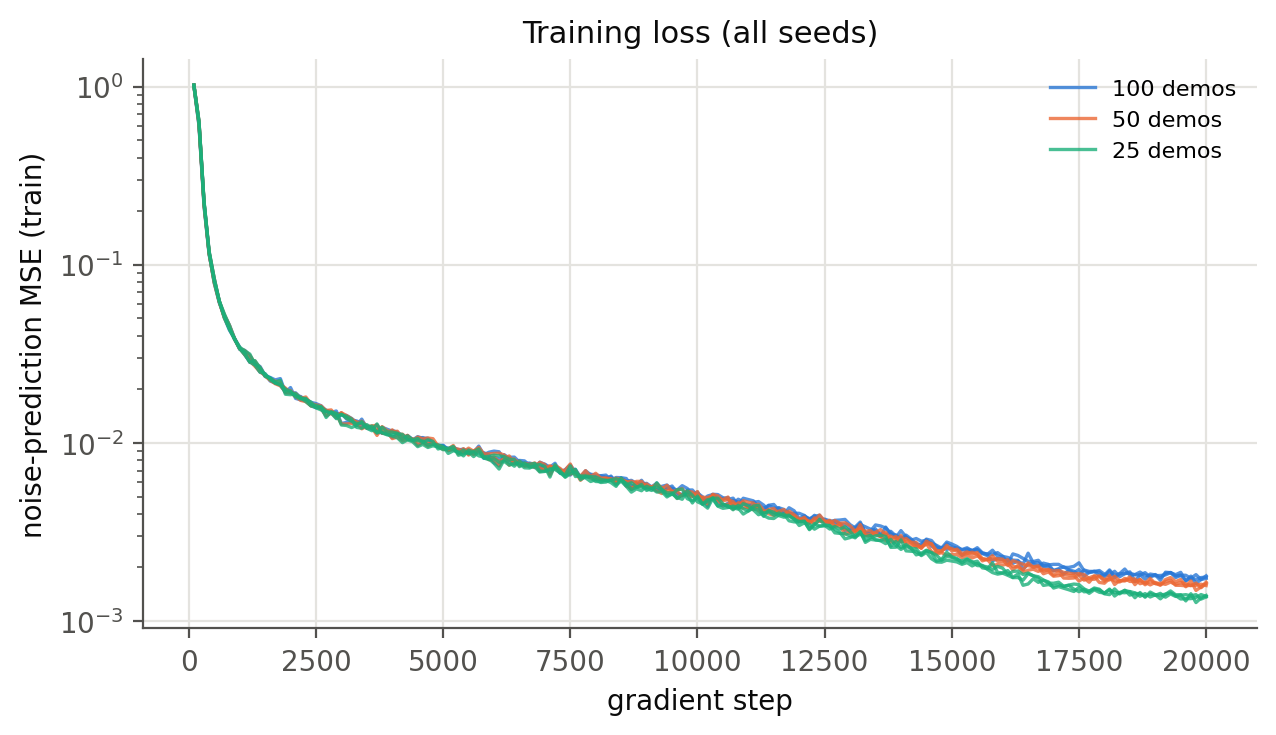

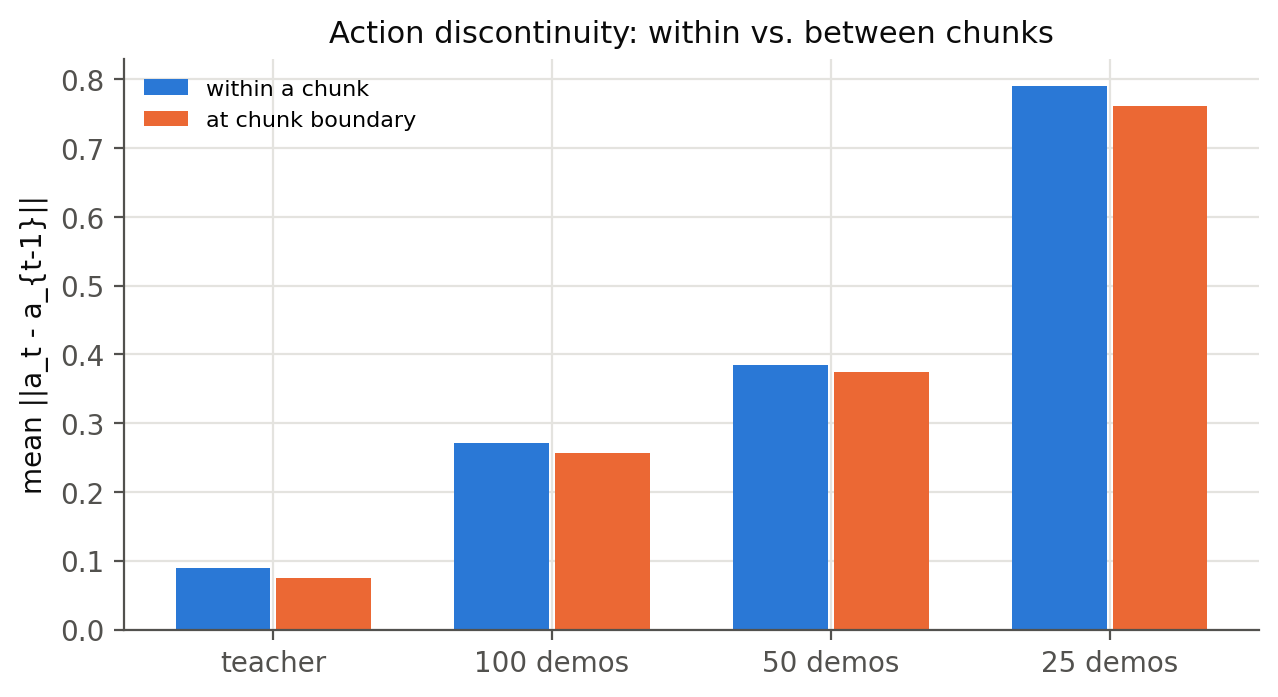

saved to Drive: /content/drive/MyDrive/CSCI-645 Homework 2/pick-and-place-swing
GitHub push skipped (no token)


In [21]:
run_command("python code/analyze.py")
display(Markdown((REPO / "results/summary_table.md").read_text()))
for figure_name in ["fig_success_vs_demos", "fig_success_vs_threshold", "fig_failure_modes",
                    "fig_loss_curves", "fig_smoothness"]:
    display(Image(str(REPO / f"results/{figure_name}.png")))
save_and_push(["results", "videos"], "results: aggregate tables and figures")

## 7. Failure analysis (Part 4)
Success vs. distance from each test layout to the closest training demo (`code/analyze_coverage.py`,
report Figure 9) and frames from student rollout videos (`code/make_rollout_figure.py`, report
Figure 6). CPU only, a few seconds; needs the results and videos from section 5.

*In the saved notebook, this cell's outputs come from running it on a laptop CPU after the Colab
session, using the same result files.*

$ python code/analyze_coverage.py
n100: 0-5 cm: 90% (n=23), 5-8 cm: 73% (n=52), 8-12 cm: 49% (n=24), 12-40 cm: 33% (n=1) | edge picks: success 55%, never reached 26% (center: 75%, 3%)
n50: 0-5 cm: 76% (n=14), 5-8 cm: 63% (n=35), 8-12 cm: 35% (n=40), 12-40 cm: 33% (n=11) | edge picks: success 29%, never reached 33% (center: 57%, 6%)
n25: 0-5 cm: 40% (n=10), 5-8 cm: 9% (n=15), 8-12 cm: 6% (n=40), 12-40 cm: 3% (n=35) | edge picks: success 6%, never reached 64% (center: 10%, 30%)
$ python code/make_rollout_figure.py
wrote results/fig_student_rollouts.png


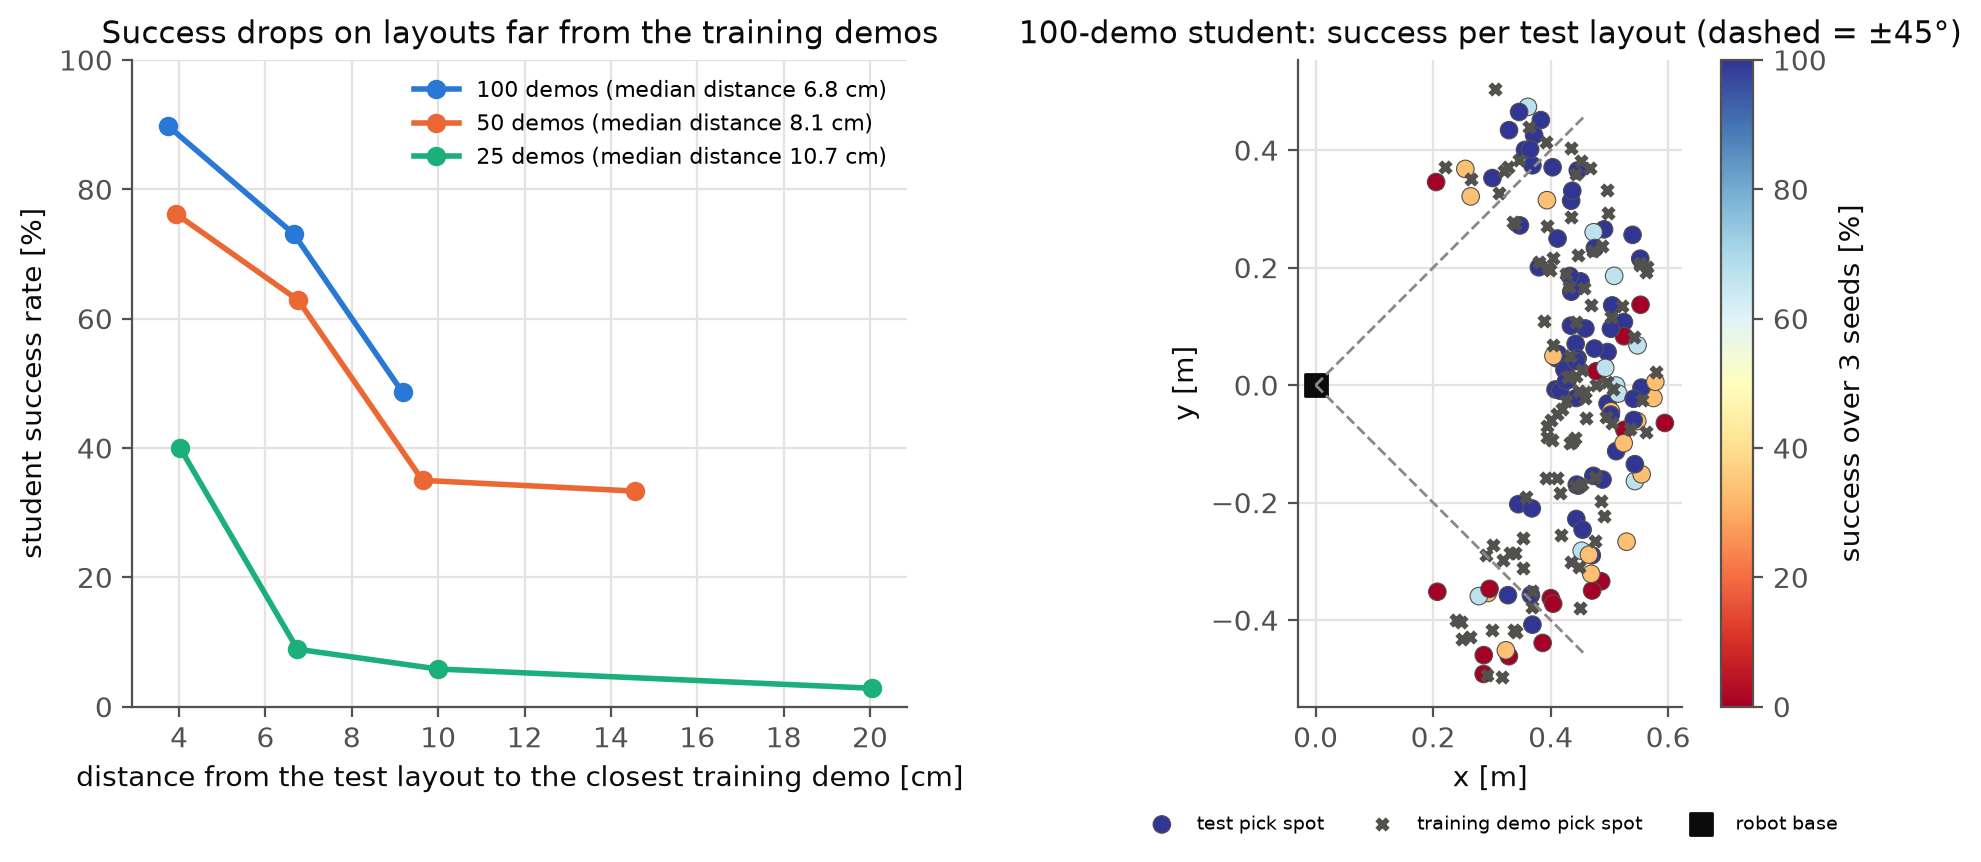

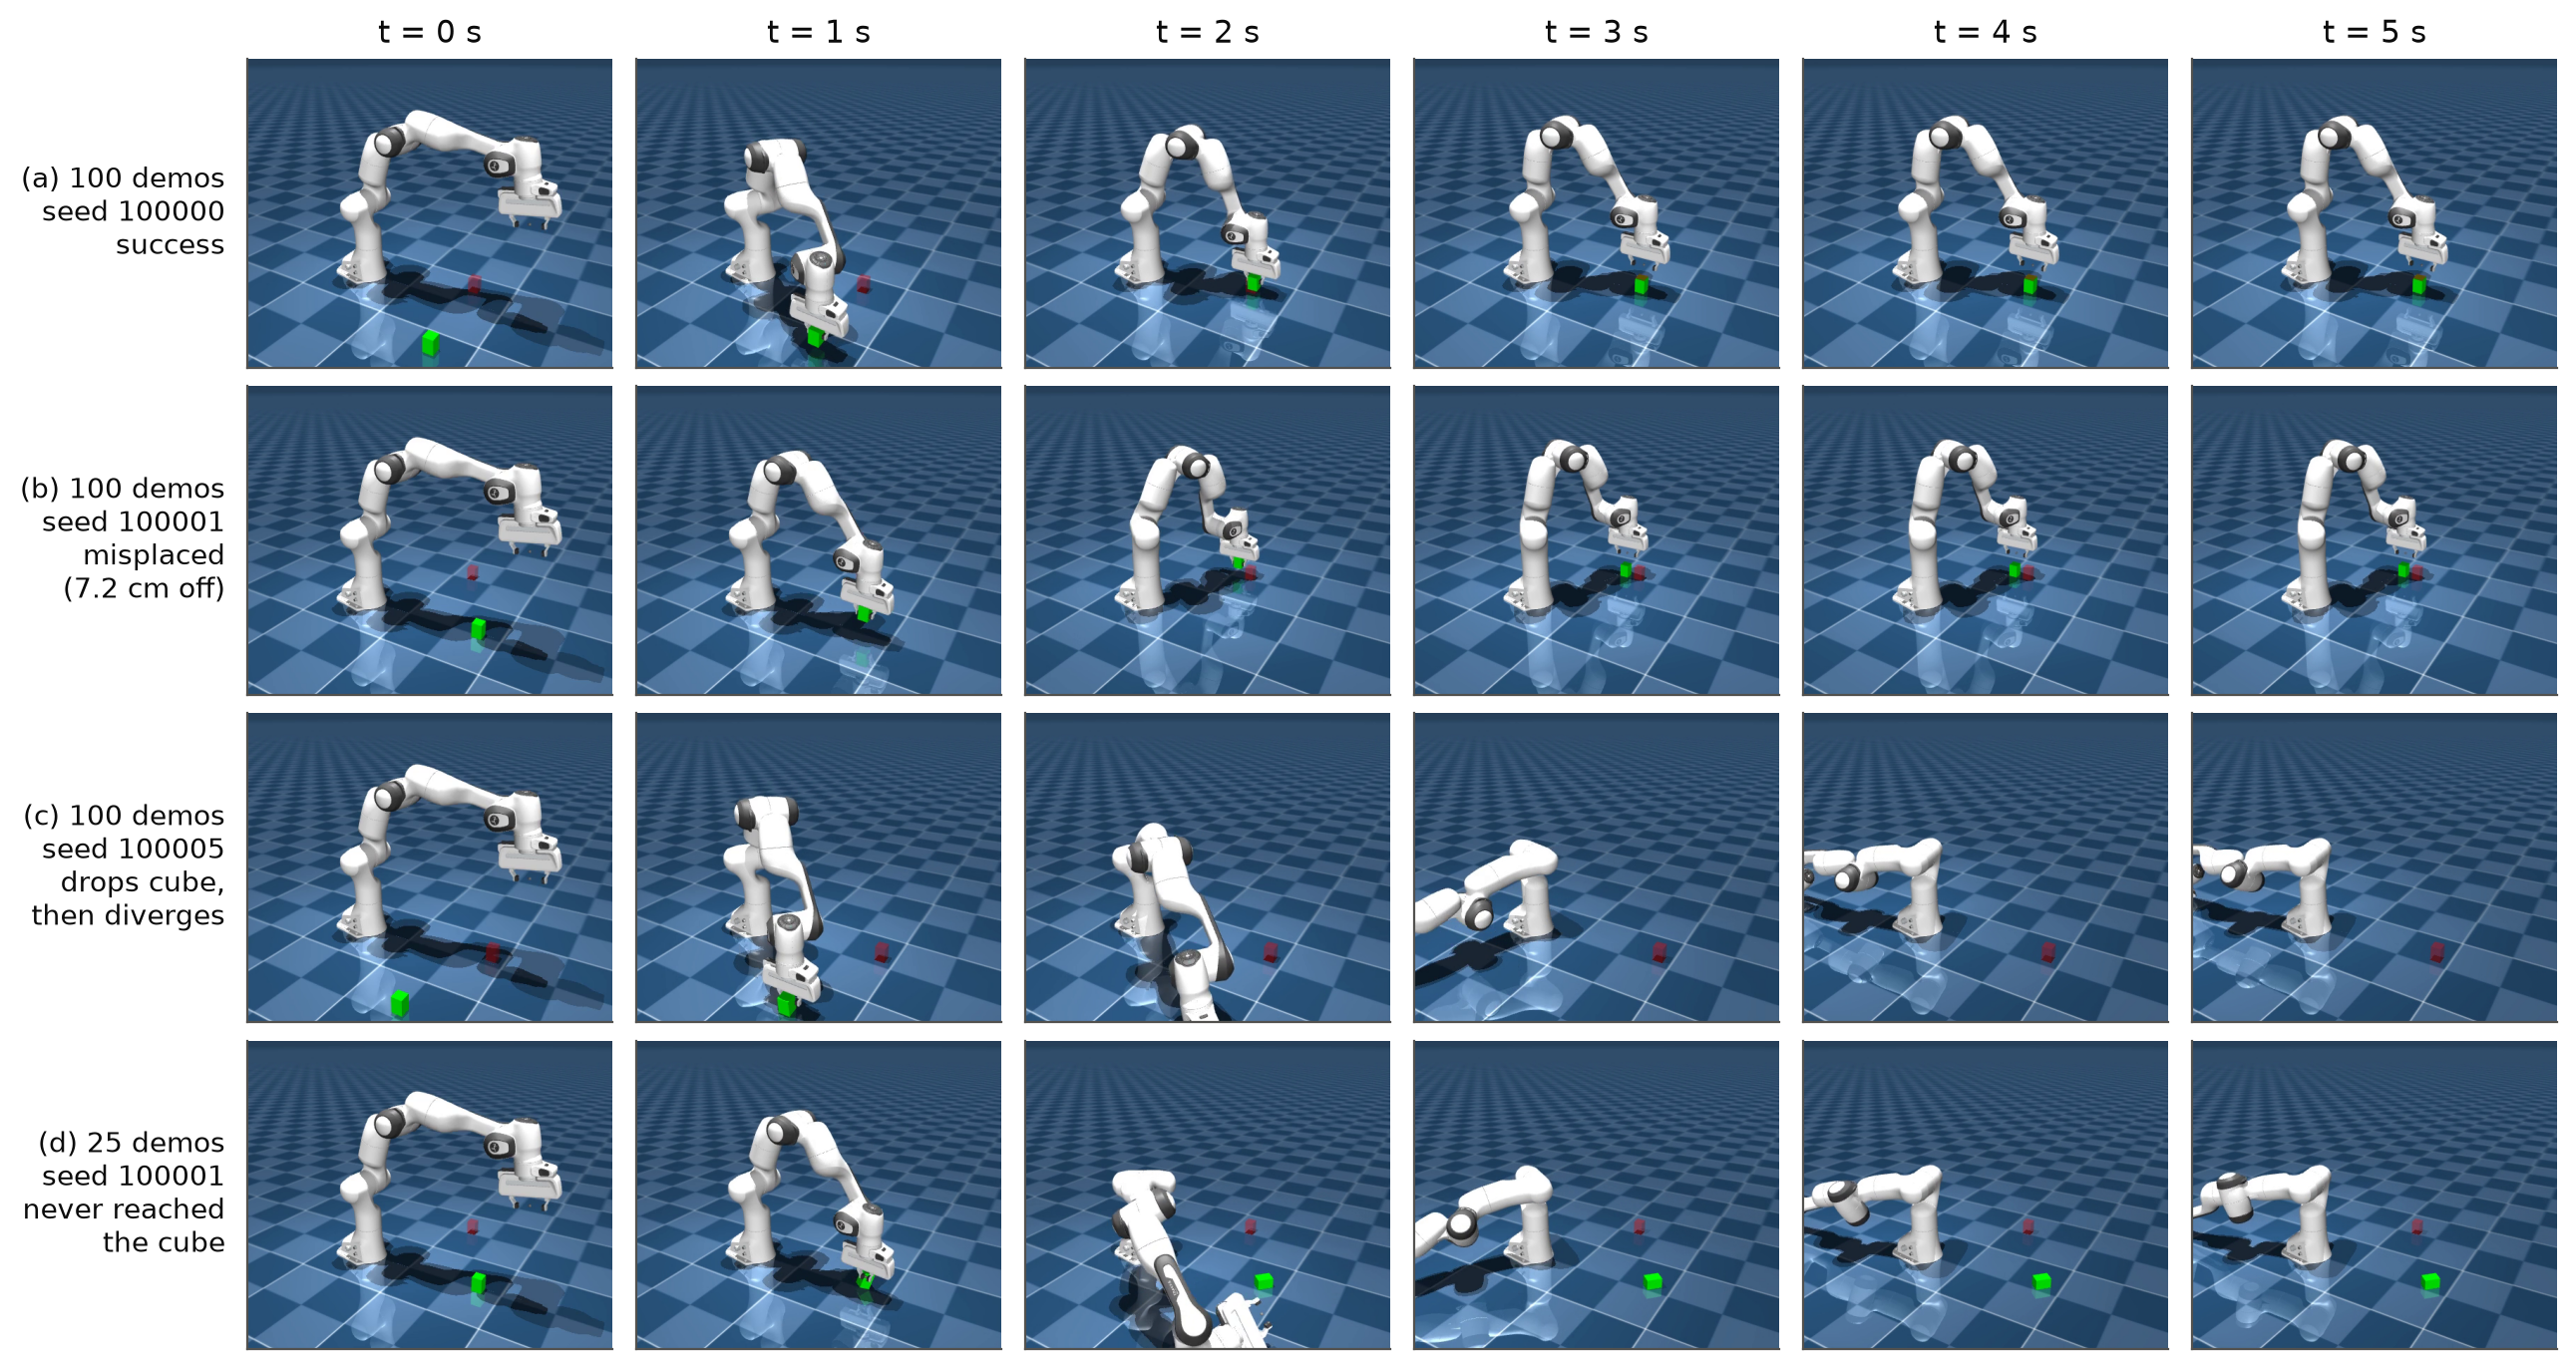

In [ ]:
run_command("python code/analyze_coverage.py")
run_command("python code/make_rollout_figure.py")
for figure_name in ["fig_coverage", "fig_student_rollouts"]:
    display(Image(str(REPO / f"results/{figure_name}.png")))
save_and_push(["results"], "results: failure analysis figures")

## 8. Save code edits
If you edited `.py` files on the runtime, review the changes and commit them before the session ends.

In [22]:
# ---- Commit any code edits made on this runtime (review the diff first!) ---------------------
run_git("status", "--short")
# save_and_push(["code", "configs"], "code: edits made on the runtime")

?? data/
?? results/
?? runs
?? videos/


CompletedProcess(args=['git', 'status', '--short'], returncode=0, stdout='?? data/\n?? results/\n?? runs\n?? videos/\n', stderr='')